In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#Get sklearn! https://scikit-learn.org/stable/
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [2]:
fileName = r"C:\Users\user\Downloads\LA_AQS_2023.csv"
df_EPA = pd.read_csv(fileName)

print(df_EPA.shape)
df_EPA.head()

(22160, 34)


,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [3]:
# Select O3 data
O3 = df_EPA[
    df_EPA['Parameter Name'] == 'Ozone'].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()

O3 = O3.rename(columns={'Arithmetic Mean': 'O3'})

# Convert O3 from ppm to ppb
O3['O3'] = O3['O3'] * 1000

O3.head()


,Date (Local),O3
0,2023-01-01,30.0600
1,2023-01-02,17.5725
2,2023-01-03,22.1175
3,2023-01-04,24.0440
4,2023-01-05,23.2755


In [4]:
# Select NO2 data
NO2 = df_EPA[
    df_EPA['Parameter Name'] == 'Nitrogen dioxide (NO2)'].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()

NO2 = NO2.rename(columns={'Arithmetic Mean': 'NO2'})

NO2.head()

,Date (Local),NO2
0,2023-01-01,4.683333
1,2023-01-02,15.068750
2,2023-01-03,11.662500
3,2023-01-04,14.363637
4,2023-01-05,11.027083


In [5]:
# Combine O3 and NO2
df_EPA = pd.merge(
    O3,
    NO2,
    on='Date (Local)'
)

df_EPA = df_EPA.dropna()

# Data creation
x = df_EPA['NO2']
y = df_EPA['O3']

print(df_EPA.shape)
df_EPA.head()

(273, 3)


,Date (Local),O3,NO2
0,2023-01-01,30.0600,4.683333
1,2023-01-02,17.5725,15.068750
2,2023-01-03,22.1175,11.662500
3,2023-01-04,24.0440,14.363637
4,2023-01-05,23.2755,11.027083


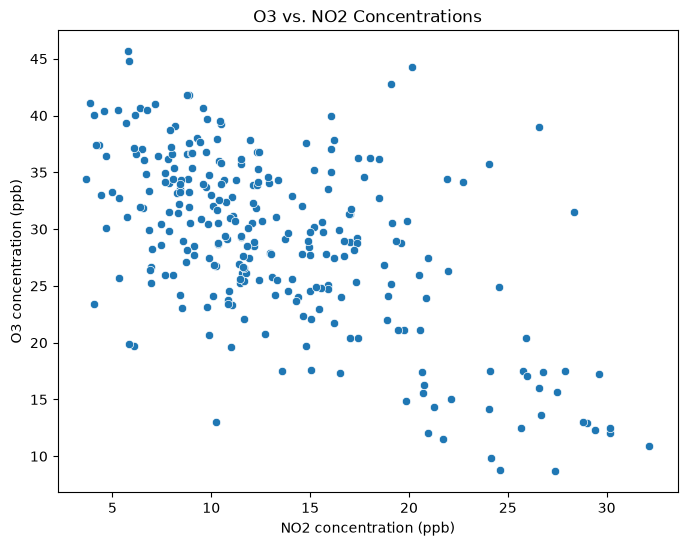

In [6]:
# Make a scatterplot
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df_EPA, x= x, y=y)

plt.xlabel('NO2 concentration (ppb)')
plt.ylabel('O3 concentration (ppb)')
plt.title('O3 vs. NO2 Concentrations')

plt.show()

In [7]:
x = df_EPA['NO2']
y = df_EPA['O3']

xVal = np.array(x).reshape((-1, 1))
yVal = np.array(y)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    xVal,
    yVal,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(218, 1)
(55, 1)


In [9]:
reg_EPA = linear_model.LinearRegression()
reg_EPA.fit(X_train, y_train);

print('Coefficient:', reg_EPA.coef_)
print('Intercept:', reg_EPA.intercept_)

Coefficient: [-0.6675389]
Intercept: 37.74753214643905


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    xVal,
    yVal,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 218
Testing observations: 55


In [11]:
# Define x and y
x = df_EPA['NO2']
y = df_EPA['O3']

# Convert x and y into arrays
xVal = np.array(x).reshape((-1, 1))
yVal = np.array(y)

In [12]:
reg = linear_model.LinearRegression()
reg.fit(xVal, yVal);

print("Coefficient:", reg.coef_)
print("Intercept:", reg.intercept_)

Coefficient: [-0.74639256]
Intercept: 38.9954886237442


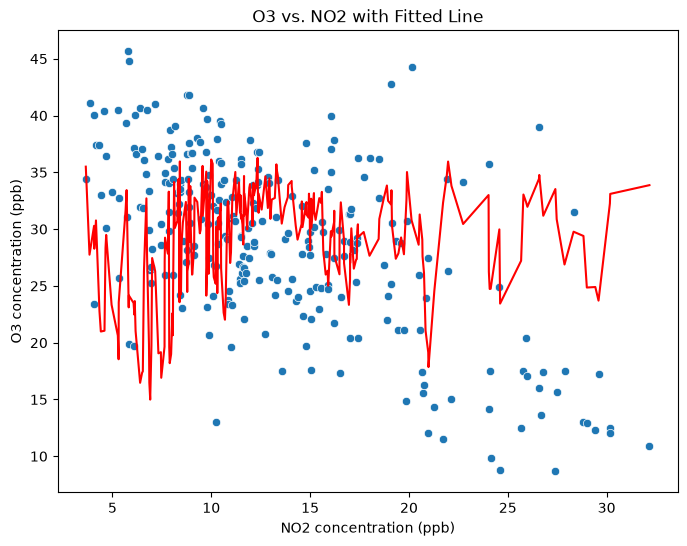

In [15]:
yPred = reg.predict(xVal)

df_EPA['yPred'] = yPred

# Sort using the NO2 column name
df_EPA = df_EPA.sort_values('NO2')

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_EPA,
    x='NO2',
    y='O3'
)

plt.plot(
    df_EPA['NO2'],
    df_EPA['yPred'],
    color='red'
)

plt.xlabel('NO2 concentration (ppb)')
plt.ylabel('O3 concentration (ppb)')
plt.title('O3 vs. NO2 with Fitted Line')

plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    xVal,
    yVal,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 218
Testing observations: 55


In [20]:
reg2 = linear_model.LinearRegression()
reg2.fit(X_train, y_train);

print("Coefficient:", reg2.coef_)
print("Intercept:", reg2.intercept_)

Coefficient: [-0.6675389]
Intercept: 37.74753214643905


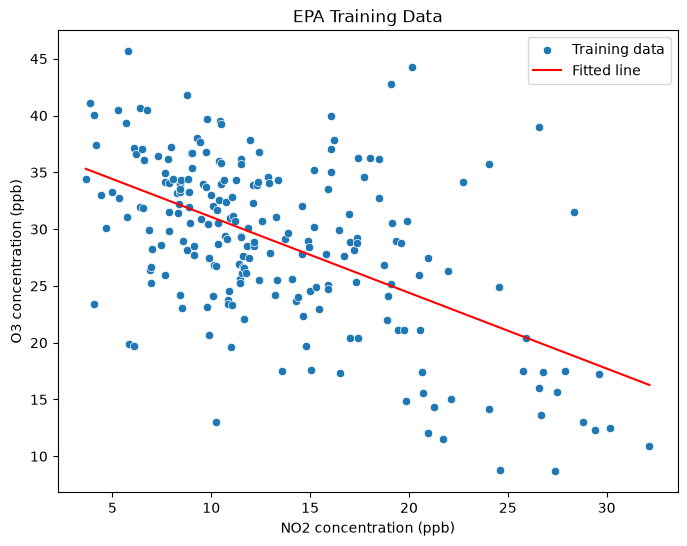

In [24]:
df_train = pd.DataFrame({
    'x': X_train.ravel(),
    'y': y_train.ravel()
})

df_train['yPred'] = reg2.predict(X_train)
df_train = df_train.sort_values('x')

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_train,
    x='x',
    y='y',
    label='Training data'
)

plt.plot(
    df_train['x'],
    df_train['yPred'],
    color='red',
    label='Fitted line'
)

plt.xlabel('NO2 concentration (ppb)')
plt.ylabel('O3 concentration (ppb)')
plt.title('EPA Training Data')
plt.legend()

plt.show()

In [25]:
df_test = pd.DataFrame({
    'x': X_test.ravel(),
    'y': y_test.ravel()
})

df_test['yPred'] = reg2.predict(X_test)
df_test = df_test.sort_values('x')

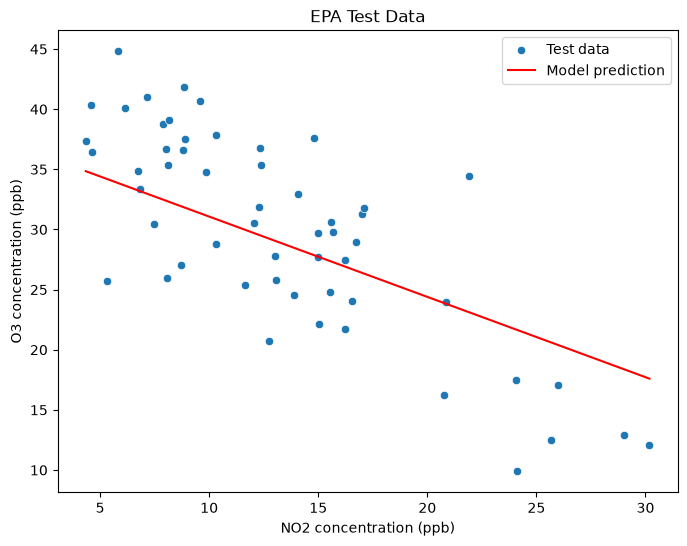

In [26]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_test,
    x='x',
    y='y',
    label='Test data'
)

plt.plot(
    df_test['x'],
    df_test['yPred'],
    color='red',
    label='Model prediction'
)

plt.xlabel('NO2 concentration (ppb)')
plt.ylabel('O3 concentration (ppb)')
plt.title('EPA Test Data')
plt.legend()

plt.show()

In [27]:
EPA_mse = mean_squared_error(
    df_test['y'],
    df_test['yPred']
)

print("EPA test MSE:", EPA_mse, "ppb²")

EPA test MSE: 32.61798899891814 ppb²


In [28]:
fileName = r"C:\Users\user\Downloads\ManuaLoa_CO2.csv"
df_LAO = pd.read_csv(fileName)

print(df_LAO.shape)
print(df_LAO.columns)
df_LAO.head()

(791, 8)
Index(['year', 'month', 'decimal date', 'average', 'deseasonalized', 'ndays',
       'sdev', 'unc'],
      dtype='str')


,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.70,314.43,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.71,-1,-9.99,-0.99
3,1958,6,1958.4548,317.24,315.14,-1,-9.99,-0.99
4,1958,7,1958.5370,315.86,315.18,-1,-9.99,-0.99


In [29]:
df_LAO.columns = df_LAO.columns.str.strip()

print(df_LAO.columns.tolist())

['year', 'month', 'decimal date', 'average', 'deseasonalized', 'ndays', 'sdev', 'unc']


In [30]:
df_before = df_LAO[df_LAO['decimal date'] < 2000]
df_after = df_LAO[df_LAO['decimal date'] >= 2000]

print('Training data:', df_before.shape)
print('Testing data:', df_after.shape)


Training data: (502, 8)
Testing data: (289, 8)


In [31]:
xVal = np.array(df_before['decimal date']).reshape((-1, 1))
yVal = np.array(df_before['average'])

In [32]:
reg_CO2 = linear_model.LinearRegression()
reg_CO2.fit(xVal, yVal);

print('Coefficient:', reg_CO2.coef_)
print('Intercept:', reg_CO2.intercept_)

Coefficient: [1.32328923]
Intercept: -2280.591072256732


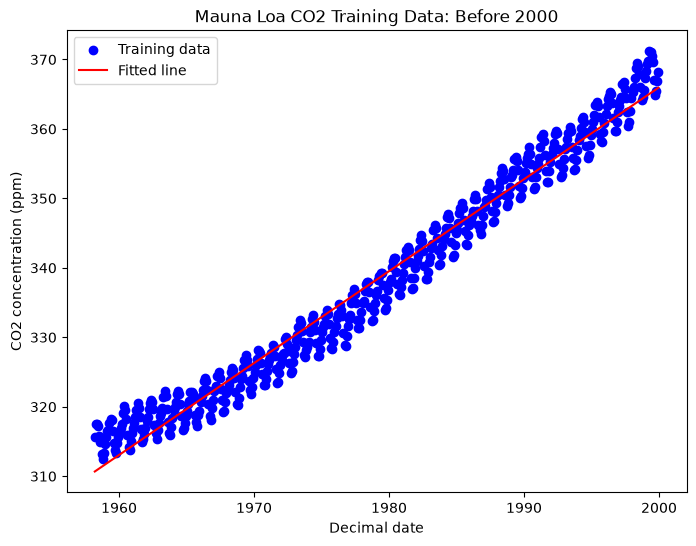

In [33]:
yPred_train = reg_CO2.predict(xVal)

plt.figure(figsize=(8, 6))

plt.scatter(
    df_before['decimal date'],
    df_before['average'],
    color='blue',
    label='Training data'
)

plt.plot(
    df_before['decimal date'],
    yPred_train,
    color='red',
    label='Fitted line'
)

plt.xlabel('Decimal date')
plt.ylabel('CO2 concentration (ppm)')
plt.title('Mauna Loa CO2 Training Data: Before 2000')
plt.legend()

plt.show()

In [34]:
xTest = np.array(df_after['decimal date']).reshape((-1, 1))
yTest = np.array(df_after['average'])

yPred = reg_CO2.predict(xTest)

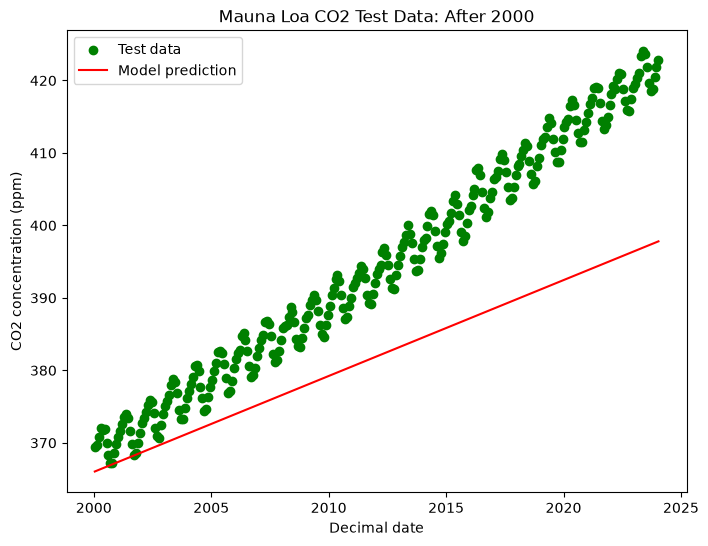

In [35]:
plt.figure(figsize=(8, 6))
plt.scatter(df_after['decimal date'], yTest, color='green', label='Test data')
plt.plot(df_after['decimal date'], yPred, color='red', label='Model prediction')

plt.xlabel('Decimal date')
plt.ylabel('CO2 concentration (ppm)')
plt.title('Mauna Loa CO2 Test Data: After 2000')
plt.legend()
plt.show()


In [36]:
CO2_mse = mean_squared_error(yTest, yPred)
print('CO2 test MSE:', CO2_mse, 'ppm²')

CO2 test MSE: 200.2461711097249 ppm²


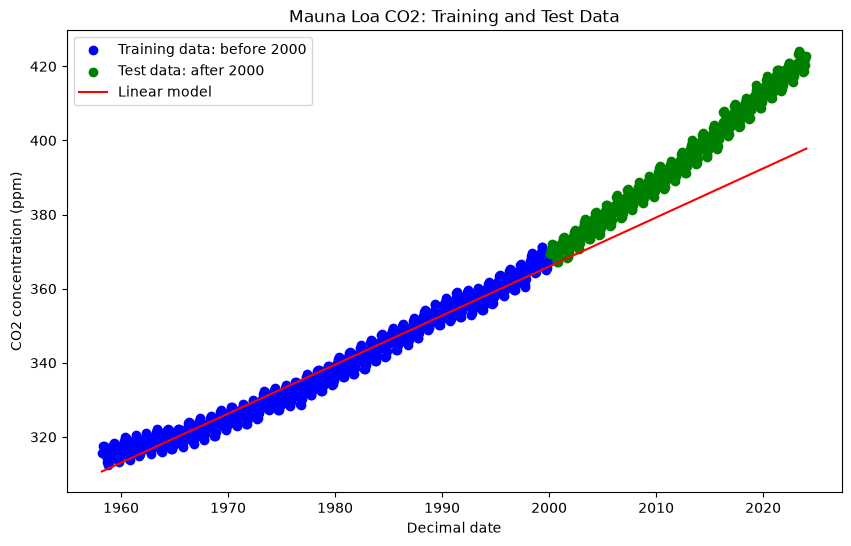

In [37]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_before['decimal date'],
    df_before['average'],
    color='blue',
    label='Training data: before 2000'
)

plt.scatter(
    df_after['decimal date'],
    df_after['average'],
    color='green',
    label='Test data: after 2000'
)

plt.plot(
    df_LAO['decimal date'],
    reg_CO2.predict(np.array(df_LAO['decimal date']).reshape((-1, 1))),
    color='red',
    label='Linear model'
)

plt.xlabel('Decimal date')
plt.ylabel('CO2 concentration (ppm)')
plt.title('Mauna Loa CO2: Training and Test Data')
plt.legend()
plt.show()
